In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Load the dataset from Kaggle.

In [2]:
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "muhammadishahrukh/nvidia-historical-stock-data",
    "nvda_stock_clean.csv",
)

df.head()

,date,ticker,open,high,low,close,volume,daily_return_pct,log_return,intraday_return_pct,daily_range_pct,overnight_gap_pct,sma_20,sma_50,volatility_20_pct,volume_sma_20,drawdown_pct,year,month,day_of_week
0,1999-01-22,NVDA,0.040018,0.044663,0.035492,0.037517,2714688000,NaN,NaN,-6.249138,22.916564,NaN,NaN,NaN,NaN,NaN,0.000000,1999,1,Friday
1,1999-01-25,NVDA,0.040494,0.041923,0.037517,0.041448,510480000,10.476402,0.099632,2.353687,10.880707,7.935928,NaN,NaN,NaN,NaN,0.000000,1999,1,Monday
2,1999-01-26,NVDA,0.041923,0.042757,0.037636,0.038231,343200000,-7.759382,-0.080770,-8.805878,12.216088,1.147548,NaN,NaN,NaN,NaN,-7.759382,1999,1,Tuesday
3,1999-01-27,NVDA,0.038350,0.039303,0.036206,0.038113,244368000,-0.311020,-0.003115,-0.620124,8.075938,0.311032,NaN,NaN,NaN,NaN,-8.046269,1999,1,Wednesday
4,1999-01-28,NVDA,0.038113,0.038350,0.037755,0.037993,227520000,-0.314385,-0.003149,-0.314397,1.562383,0.000012,NaN,NaN,NaN,NaN,-8.335358,1999,1,Thursday


In [7]:
df.shape

(6958, 20)

In [9]:
df.dtypes

date                    object
ticker                  object
open                   float64
high                   float64
low                    float64
close                  float64
volume                   int64
daily_return_pct       float64
log_return             float64
intraday_return_pct    float64
daily_range_pct        float64
overnight_gap_pct      float64
sma_20                 float64
sma_50                 float64
volatility_20_pct      float64
volume_sma_20          float64
drawdown_pct           float64
year                     int64
month                    int64
day_of_week             object
dtype: object

First, let us take a look at the evolution of the price of the NVIDIA assets throughout the years.

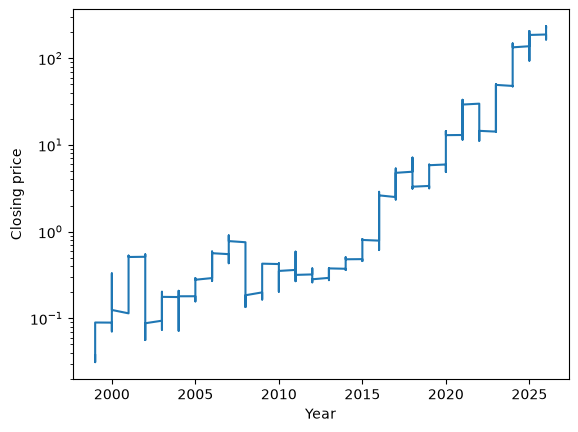

In [8]:
plt.plot(df.year, df.close)
plt.yscale("log")
plt.ylabel("Closing price")
plt.xlabel("Year")
plt.show()

In [19]:
df.isna().sum()[df.isna().sum()>0]

daily_return_pct      1
log_return            1
overnight_gap_pct     1
sma_20               19
sma_50               49
volatility_20_pct    20
volume_sma_20        19
dtype: int64

In this case, I define the target variable as the return percentage of the assets from one week to the next.

In [3]:
df["weekly_return_pct"] = df["close"].shift(-7) / df["close"] - 1
df = df.iloc[7:]

<Axes: xlabel='weekly_return_pct', ylabel='Count'>

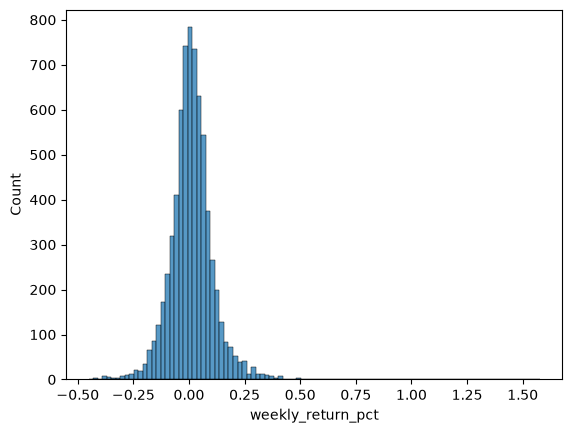

In [10]:
sns.histplot(data=df.weekly_return_pct, bins=100)

<Axes: xlabel='weekly_return_pct', ylabel='Count'>

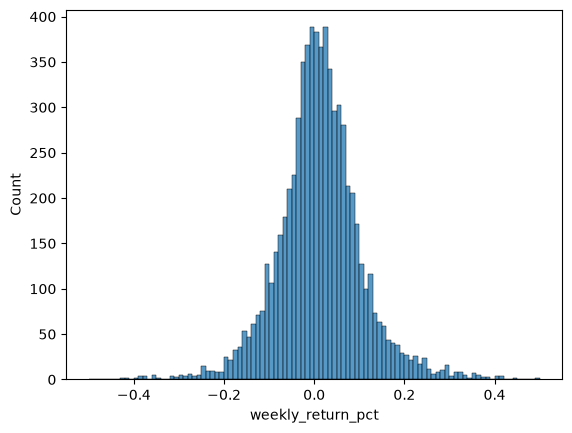

In [11]:
sns.histplot(data=df.weekly_return_pct, bins=100, binrange=(-0.5, 0.5))

Now, let's clean the dataset to make more exploratory data anallysis.

In [4]:
#We can fill the missing values of these variables with their average value.
for var in ["sma_20", "sma_50", "volatility_20_pct", "volume_sma_20", "weekly_return_pct"]:
    avr = df[var].mean()
    df[var] = df[var].fillna(avr)

Let's make some feature importance. The "date" is just the identifying label for each row, and "ticker" has a unique value (the brand's name). So they won't be used to train a model.

In [22]:
print(df.ticker.value_counts())

ticker
NVDA    6958
Name: count, dtype: int64


Regarding the remaining variables, many of them are functions of others. Concretely,

daily_return_pct, 
log_return, 
intraday_return_pct, 
overnight_gap_pct, 
sma_20, 
sma_50, 
volatility_20_pct, 
volume_sma_20, 
drawdown_pct,

are directly computed from the following variables:

open, 
high, 
low, 
close, 
volume,
day_of_week,
month.

This means, the only fully independent variables are the openning, closing, highest and lowest prices of the assets in the date, the trading volume, and, maybe less determinant, the day of the week and month. However, we should not hurry up to discard the other variables, since some of them contain information about the recent time evolution of the assets. This is, they are not only functions of the variables for the corresponding date, but they involve data from previous time periods, somehow containing memory information. We can discard the variables that are explicit functions of the mentioned independent variables for the same date, since they do not provide additional information. Only intraday_return_pct fulfills this description. To test the relevance of the other variables, I train a decision tree regressor including and then excluding them and compare the RMSE score.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor

In [7]:
df_train, df_val = train_test_split(
    df, test_size=0.3, random_state=1
)

In [23]:
train_dict = df_train.drop(['weekly_return_pct'], axis=1).to_dict(orient='records')
val_dict = df_val.drop(['weekly_return_pct'], axis=1).to_dict(orient='records')

pipeline = make_pipeline(
    DictVectorizer(sparse=False),
    DecisionTreeRegressor(max_depth=10)
)

pipeline.fit(train_dict, df_train['weekly_return_pct'])
y_pred = pipeline.predict(val_dict)
print("RMSE: ", root_mean_squared_error(df_val['weekly_return_pct'], y_pred))

RMSE:  0.0989298761802495


Now, I train the model again using only the variables open, high, low, close, volume, day_of_week, and month.

In [10]:
train_dict = df_train[['open', 'high', 'low', 'close', 'volume', 'day_of_week', 'month']].to_dict(orient='records')
val_dict = df_val[['open', 'high', 'low', 'close', 'volume', 'day_of_week', 'month']].to_dict(orient='records')

In [8]:
pipeline = make_pipeline(
    DictVectorizer(sparse=False),
    DecisionTreeRegressor(max_depth=10)
)

pipeline.fit(train_dict, df_train['weekly_return_pct'])
y_pred = pipeline.predict(val_dict)
print("RMSE: ", root_mean_squared_error(df_val['weekly_return_pct'], y_pred))

RMSE:  0.10772470722831734


As we can see, using only these variables increases the RMSE by around 2%. To speed up running time, I will then use these variables for model selection and parameter tuning, and for the final model I will include all the input variables to improve model's accuracy.

Now, I explore different models. I try Linear Regression, Random Forest, and Gradient Boosting.

In [31]:
pipeline = make_pipeline(
    DictVectorizer(sparse=False),
    LinearRegression()
)

pipeline.fit(train_dict, df_train['weekly_return_pct'])
y_pred = pipeline.predict(val_dict)
print("RMSE: ", root_mean_squared_error(df_val['weekly_return_pct'], y_pred))

RMSE:  0.10364117159372133


Now, I try with Random Forest. I also make some parameter tuning.

In [32]:
for n in [10, 50, 100, 150]:
    pipeRF = make_pipeline(
    DictVectorizer(sparse=False),
    RandomForestRegressor(n_estimators=n, random_state=1)
    )

    pipeRF.fit(train_dict, df_train['weekly_return_pct'])
    y_pred = pipeRF.predict(val_dict)
    print(f"RMSE for {n} trees: ", root_mean_squared_error(df_val['weekly_return_pct'], y_pred))

RMSE for 10 trees:  0.09269337185154432
RMSE for 50 trees:  0.0897512306191286
RMSE for 100 trees:  0.08971838329779902
RMSE for 150 trees:  0.08949705451625015


It will be sufficient with a sample of 50 trees.

In [34]:
for md in [10, 15, 20, 25]:
    pipeRF = make_pipeline(
        DictVectorizer(sparse=False),
        RandomForestRegressor(n_estimators=50, max_depth=md, random_state=1)
    )

    pipeRF.fit(train_dict, df_train['weekly_return_pct'])
    y_pred = pipeRF.predict(val_dict)
    
    print(f"RMSQ for maximum depth {md}: ", root_mean_squared_error(df_val['weekly_return_pct'], y_pred))

Mean RMSE for max_depth:
10 :  RMSQ for maximum depth 10:  0.09305575318146263
15 :  RMSQ for maximum depth 15:  0.09122425862290925
20 :  RMSQ for maximum depth 20:  0.09012059405783429
25 :  RMSQ for maximum depth 25:  0.09019106567698518


I will set the maximum depth as 20.

In [35]:
for sl in [2, 5, 10, 20]:
    pipeRF = make_pipeline(
        DictVectorizer(sparse=False),
        RandomForestRegressor(n_estimators=50, max_depth=20, min_samples_leaf=sl, random_state=1)
    )

    pipeRF.fit(train_dict, df_train['weekly_return_pct'])
    y_pred = pipeRF.predict(val_dict)
    
    print(f"RMSQ for minimum samples per leaf node {sl}: ", root_mean_squared_error(df_val['weekly_return_pct'], y_pred))

RMSQ for minimum samples per leaf node 2:  0.08978847494799791
RMSQ for minimum samples per leaf node 5:  0.09067527714998376
RMSQ for minimum samples per leaf node 10:  0.09309684763244816
RMSQ for minimum samples per leaf node 20:  0.09561993768838134


It seems that increasing the minimum number of samples per laef node does not improve the model. So I keep this at its default value of 2.

Now, I try with Gradient Boosting.

In [12]:
import xgboost as xgb
import io
from contextlib import redirect_stdout

In [13]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=df_train['weekly_return_pct'], feature_names=features)
dval = xgb.DMatrix(X_val, label=df_val['weekly_return_pct'], feature_names=features)

watchlist = [(dtrain, 'train'), (dval, 'val')]

Parameter tuning.

In [25]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    
    'seed': 1,
    'verbosity': 1,
}
evals_result = {}
model = xgb.train(xgb_params, dtrain, num_boost_round=500, evals=watchlist, evals_result=evals_result, verbose_eval=False)

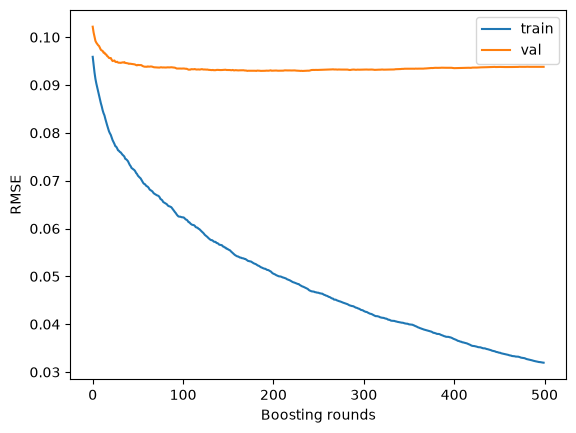

In [26]:
plt.plot(evals_result['train']['rmse'], label='train')
plt.plot(evals_result['val']['rmse'], label='val')
plt.xlabel('Boosting rounds')
plt.ylabel('RMSE')
plt.legend()

As we can see, the validation rmse score reaches a stationary value much earlier than the training score. So we use the stationarity of the validation score as a stopping criterion. Now, let us make some parameter tuning.

In [29]:
eta_values = [1., 0.3, 0.1, 0.05, 0.01]
mx_rds = 100
scores = np.zeros((mx_rds, len(eta_values)))

for i, eta in enumerate(eta_values):
    xgb_params = {
        'eta': eta, 
        'max_depth': 6,
        'min_child_weight': 1,
        
        'objective': 'reg:squarederror',
        
        'seed': 1,
        'verbosity': 1,
    }
    evals_result = {}
    model = xgb.train(xgb_params, dtrain, num_boost_round=mx_rds, evals=watchlist, evals_result=evals_result, verbose_eval=False)

    scores[:, i] = evals_result['val']['rmse']

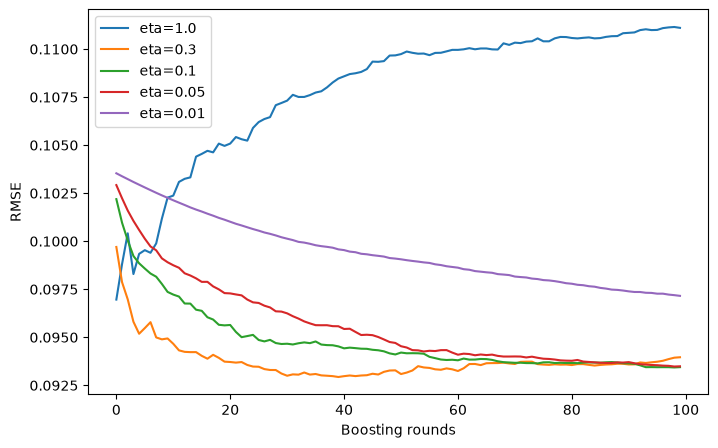

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))

for i, eta in enumerate(eta_values):
    ax.plot(scores[:, i], label=f'eta={eta}')

ax.set_xlabel('Boosting rounds')
ax.set_ylabel('RMSE')
ax.legend()

In [39]:
md_values = [3,8,10,15,20]
scores = np.zeros((mx_rds, len(eta_values)))

for i, md in enumerate(md_values):
    xgb_params = {
        'eta': 0.3, 
        'max_depth': md,
        'min_child_weight': 1,
        
        'objective': 'reg:squarederror',
        
        'seed': 1,
        'verbosity': 1,
    }
    evals_result = {}
    model = xgb.train(xgb_params, dtrain, num_boost_round=mx_rds, evals=watchlist, evals_result=evals_result, verbose_eval=False)

    scores[:, i] = evals_result['val']['rmse']

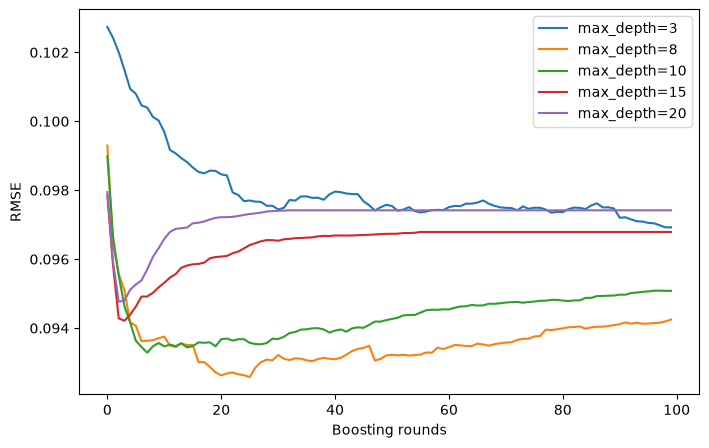

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))

for i, md in enumerate(md_values):
    ax.plot(scores[:, i], label=f'max_depth={md}')

ax.set_xlabel('Boosting rounds')
ax.set_ylabel('RMSE')
ax.legend()

In [42]:
min_child_weight_values = [1, 5, 10, 20, 30]

scores = np.zeros((mx_rds, len(eta_values)))

for i, mcw in enumerate(min_child_weight_values):
    xgb_params = {
        'eta': 0.3, 
        'max_depth': 8,
        'min_child_weight': mcw,
        
        'objective': 'reg:squarederror',
        
        'seed': 1,
        'verbosity': 1,
    }
    evals_result = {}
    model = xgb.train(xgb_params, dtrain, num_boost_round=mx_rds, evals=watchlist, evals_result=evals_result, verbose_eval=False)

    scores[:, i] = evals_result['val']['rmse']

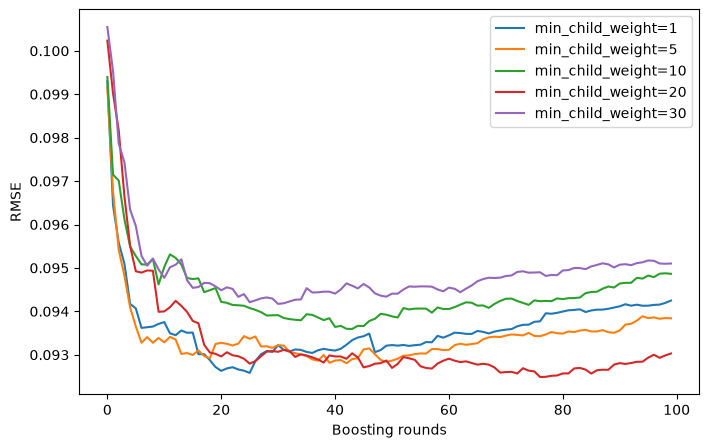

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))

for i, mcw in enumerate(min_child_weight_values):
    ax.plot(scores[:, i], label=f'min_child_weight={mcw}')

ax.set_xlabel('Boosting rounds')
ax.set_ylabel('RMSE')
ax.legend()

Finally, I train the model with the set of parameters that proved to be the best in the above tests.

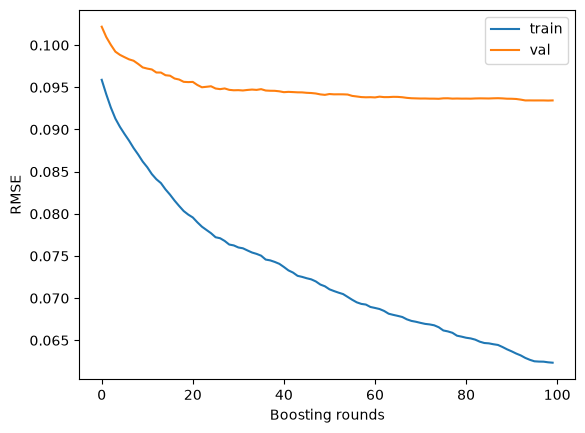

In [46]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    
    'seed': 1,
    'verbosity': 1,
}
evals_result = {}
model = xgb.train(xgb_params, dtrain, num_boost_round=mx_rds, evals=watchlist, evals_result=evals_result, verbose_eval=False)

plt.plot(evals_result['train']['rmse'], label='train')
plt.plot(evals_result['val']['rmse'], label='val')
plt.xlabel('Boosting rounds')
plt.ylabel('RMSE')
plt.legend()

In [47]:
print(evals_result['val']['rmse'][-1])

0.09344699161727006


Summarizing, the best scores for each method were:

- Linear Regression: 0.104
- Random Forest: 0.090
- Gradient Boosting: 0.093

Then, I choose Random Forest. Before training the final model, I try another thing. In finance, it seems that it is common to use a chronological splitting rather than random splitting. I compare the scores with both methods.